# EDA для стенда тестирования навыков

Стенд будет гонять Claude Code на сценариях с документами и данными, с навыком и без него, и сравнивать версии навыков. Своих логов у нас пока нет, они появятся на этапе бейзлайна. Поэтому я смотрю на ближайшие открытые данные, результаты бенчмарка [SkillsBench](https://arxiv.org/abs/2602.12670). Формат там тот же, что будет у нас. Задача запускается в Docker, у нее есть входные файлы и проверка результата кодом, на каждое условие три запуска, и есть логи Claude Code.

Вопросы, на которые отвечает этот ноутбук.

1. Сколько данных и какого они качества.
2. Насколько расходятся повторные запуски и сколько повторов нам нужно.
3. Как часто навык помогает, а как часто мешает.
4. Видно ли по логу, какой навык открыл агент.
5. Сколько идет запуск и уложится ли проверка PR в 40 минут.
6. Что видно о причинах провалов и об описаниях навыков.

Данные скачивает `scripts/fetch_eda_data.py`, таблицы собирает `scripts/build_eda_tables.py`. Версии источников зафиксированы, описание таблиц лежит в [`data/README.md`](../data/README.md).

In [1]:
import heapq
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from skills_testbed.stats import minimum_detectable_effect

DATA = Path("../data/processed")
BLUE, ORANGE, GRAY = "#2b6cb0", "#dd6b20", "#a0aec0"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.titlesize": 10,
    }
)
pd.set_option("display.precision", 2)

tasks = pd.read_csv(DATA / "tasks.csv")
skills = pd.read_csv(DATA / "skills.csv")
trials = pd.read_csv(DATA / "trials.csv").merge(tasks[["task", "doc_data"]], on="task")
cc = pd.read_csv(DATA / "claude_code_runs.csv").merge(
    tasks[["task", "doc_data", "n_skills"]], on="task"
)
audit = pd.read_csv(DATA / "failure_audit.csv")
openhands_use = pd.read_csv(DATA / "openhands_skill_use.csv")

trials["passed"] = (trials.status == "pass").astype(int)
trials["config"] = trials.harness + " / " + trials.model
cc["passed"] = (cc.status == "pass").astype(int)

## 1. Состав и объем

Сущности те же, что будут в стенде. Задача это наш сценарий, навык это папка со SKILL.md, запуск это один прогон агента с логом и итоговой проверкой. Задачи на документы и данные это категории office-white-collar и finance-economics, так же, как в дизайн-документе.

In [2]:
summary = pd.Series(
    {
        "Задачи": len(tasks),
        "из них на документы и данные": int(tasks.doc_data.sum()),
        "Навыки": len(skills),
        "разных названий навыков": skills.skill.nunique(),
        "Запуски всех агентов и моделей": len(trials),
        "конфигураций агент и модель": trials.config.nunique(),
        "Запуски Claude Code с полным логом": len(cc),
    },
    name="Сколько",
)
summary.to_frame()

,Сколько
Задачи,87
из них на документы и данные,23
Навыки,232
разных названий навыков,195
Запуски всех агентов и моделей,6513
конфигураций агент и модель,22
Запуски Claude Code с полным логом,432


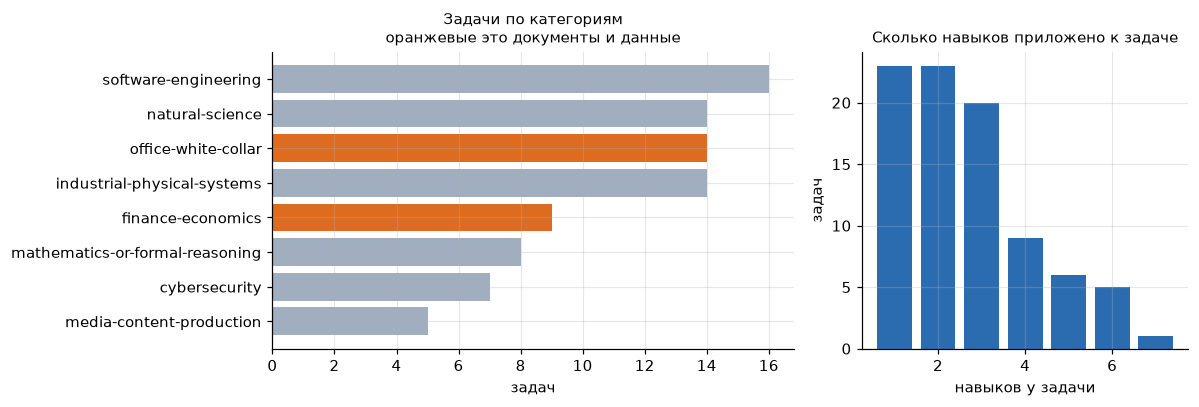

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), width_ratios=[1.6, 1])
by_cat = tasks.category.value_counts().sort_values()
doc_categories = {"office-white-collar", "finance-economics"}
colors = [ORANGE if c in doc_categories else GRAY for c in by_cat.index]
ax1.barh(by_cat.index, by_cat.values, color=colors)
ax1.set_title("Задачи по категориям\nоранжевые это документы и данные")
ax1.set_xlabel("задач")
per_task = tasks.n_skills.value_counts().sort_index()
ax2.bar(per_task.index, per_task.values, color=BLUE)
ax2.set_title("Сколько навыков приложено к задаче")
ax2.set_xlabel("навыков у задачи")
ax2.set_ylabel("задач")
fig.tight_layout()

In [4]:
skills.skill.value_counts().head(5).rename("в скольких задачах").to_frame()

,в скольких задачах
skill,
xlsx,13
pdf,11
power-flow-data,3
pptx,3
obspy-data-api,2


**Вывод.** В бенчмарке 87 задач, на документы и данные приходится 23. К задаче приложено от 1 до 7 навыков, чаще всего 1 или 2. Навыки xlsx и pdf встречаются в 13 и 11 задачах. Это старые версии стандартных навыков Anthropic, тех же, что мы берем в MVP.

Для стенда этих данных мало. 23 задачи на документы дают слабую чувствительность, а задач, где навык не нужен, и навыков с похожими описаниями в SkillsBench нет. Поэтому SkillsBench подходит, чтобы оценить шум, время и поведение агента, а сценарии стенда нужно делать самим.

## 2. Качество данных

Смотрю, чего не хватает в данных и что в них мешает честному сравнению. Цель по каждой конфигурации это 87 задач, 2 режима и 3 запуска, то есть 522 запуска.

In [5]:
cells = trials.groupby(["config", "task", "mode"]).size()
timeout_runs = cc[cc.status == "timeout"]
issues = pd.Series(
    {
        "Задачи без единого запуска": f"{len(set(tasks.task) - set(trials.task))} из {len(tasks)}",
        "Ячейки задача и режим, где меньше 3 запусков": f"{(cells < 3).mean():.0%}",
        "Запуски, упавшие по таймауту": f"{(trials.status == 'timeout').mean():.0%}",
        "Таймауты без итоговой награды": (
            f"{trials[trials.status == 'timeout'].reward.isna().mean():.0%}"
        ),
        "Таймауты Claude Code без времени агента": (
            f"{timeout_runs.agent_s.isna().sum()} из {len(timeout_runs)}"
        ),
        "Запуски без токенов и цены": f"{1 - trials.has_tokens.mean():.0%}",
        "Запуски с частичной наградой между 0 и 1": int(trials.reward.between(0.01, 0.99).sum()),
        "Запуски без навыков, где агент все равно открыл навык": int(
            (cc[cc["mode"] == "without"].n_skill_calls > 0).sum()
        ),
        "Логи Claude Code с ошибкой запуска": int(cc.run_error.sum()),
        "Логи Claude Code, обрезанные на середине": int(cc.partial_log.sum()),
    },
    name="Значение",
)
issues.to_frame()

,Значение
Задачи без единого запуска,15 из 87
"Ячейки задача и режим, где меньше 3 запусков",23%
"Запуски, упавшие по таймауту",23%
Таймауты без итоговой награды,69%
Таймауты Claude Code без времени агента,33 из 43
Запуски без токенов и цены,100%
Запуски с частичной наградой между 0 и 1,262
"Запуски без навыков, где агент все равно открыл навык",3
Логи Claude Code с ошибкой запуска,48
"Логи Claude Code, обрезанные на середине",38


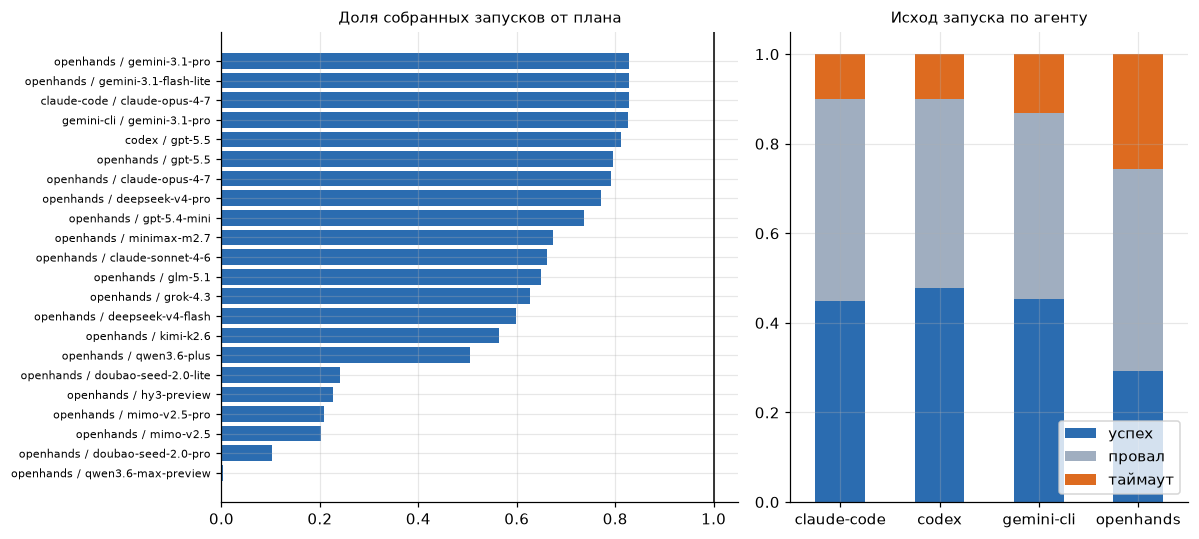

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), width_ratios=[1.3, 1])
coverage = trials.groupby("config").size().sort_values() / 522
ax1.barh(coverage.index, coverage.values, color=BLUE)
ax1.axvline(1, color="black", lw=1)
ax1.set_title("Доля собранных запусков от плана")
ax1.tick_params(axis="y", labelsize=7)
status = pd.crosstab(trials.harness, trials.status, normalize="index")[["pass", "fail", "timeout"]]
status.plot.bar(stacked=True, ax=ax2, color=[BLUE, GRAY, ORANGE], rot=0)
ax2.set_title("Исход запуска по агенту")
ax2.set_xlabel("")
ax2.legend(["успех", "провал", "таймаут"], loc="lower right")
fig.tight_layout()

In [7]:
counted = trials.passed.mean()
excluded = trials[trials.status != "timeout"].passed.mean()
print(f"Доля успеха, если таймаут это провал   {counted:.1%}")
print(f"Доля успеха, если таймауты выбросить  {excluded:.1%}")

Доля успеха, если таймаут это провал   32.5%
Доля успеха, если таймауты выбросить  42.1%


**Вывод.** Данные заметно дырявые. В 15 задачах нет ни одного запуска, у четверти ячеек меньше трех повторов, почти четверть запусков упала по таймауту. Для таймаутов часто нет ни награды, ни времени агента.

Почти все эти проблемы будут и у нас, поэтому стенд должен ловить их сам.

1. Таймаут считаем провалом с причиной «таймаут», а не выбрасываем. Официальный подсчет SkillsBench таймауты выбрасывает, и доля успеха от этого растет с 33% до 42%. Если одна версия навыка чаще упирается в лимит времени, такое правило спрячет ее поломку.
2. Токенов и цены нет ни в одном запуске. Стенд пишет цену сам из вывода Claude Code (`total_cost_usd`).
3. В 3 запусках без навыков агент открыл навык radar-vital-signs. Значит, навык попал в окружение, хотя не должен был. Стенд проверяет каждый такой запуск и помечает его как недействительный.
4. Неполные логи и ошибки запуска бывают примерно в каждом десятом запуске. Это причина «сбой инфраструктуры», и такие запуски не идут в сравнение версий.
5. Награда бывает частичной. Успехом считаем только полную проверку, как и в SkillsBench.

## 3. Разброс между повторами

Беру ячейки, где у задачи в одном режиме ровно три запуска, и смотрю, сколько из них успешны. Если все три одинаковы, повтор ничего не добавил. Дальше считаю средний разброс p(1-p), где p это доля успехов в ячейке. Это дисперсия одного запуска, и от нее зависит, какое падение тест заметит.

In [8]:
cell = (
    trials.groupby(["config", "task", "mode"])
    .agg(n=("passed", "size"), k=("passed", "sum"), doc=("doc_data", "first"))
    .reset_index()
)
three = cell[cell.n == 3].copy()
three["var"] = three.k * (3 - three.k) / 6  # unbiased p(1-p) for 3 runs
stats = three.groupby("doc").agg(
    cells=("k", "size"),
    all_three_same=("k", lambda k: k.isin([0, 3]).mean()),
    mean_var=("var", "mean"),
)
stats.index = ["остальные задачи", "документы и данные"]
stats

,cells,all_three_same,mean_var
остальные задачи,1362,0.72,0.09
документы и данные,535,0.74,0.09


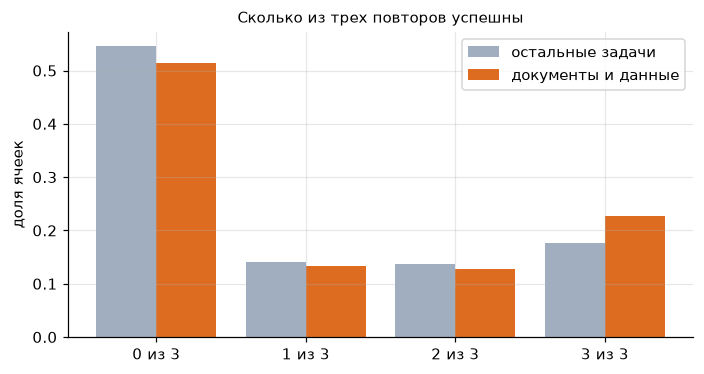

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
share = pd.crosstab(three.k, three.doc, normalize="columns")
x = np.arange(4)
ax.bar(x - 0.2, share[False], 0.4, color=GRAY, label="остальные задачи")
ax.bar(x + 0.2, share[True], 0.4, color=ORANGE, label="документы и данные")
ax.set_xticks(x, ["0 из 3", "1 из 3", "2 из 3", "3 из 3"])
ax.set_ylabel("доля ячеек")
ax.set_title("Сколько из трех повторов успешны")
ax.legend()
fig.tight_layout()

Теперь посчитаю, какое падение доли успеха заметит парный тест при таком разбросе. Это минимальный заметный эффект (MDE) при уровне 5% и мощности 80%, формула лежит в `skills_testbed.stats`. Это нижняя граница, потому что разницу в эффекте между сценариями формула не учитывает.

Чтобы заметить падение 15 п.п. при 3 повторах, нужно 16 сценариев
Чтобы заметить падение 15 п.п. при 5 повторах, нужно 10 сценариев


,3 повторов,5 повторов
6 сценариев,24,19
12 сценариев,17,13
60 сценариев,8,6


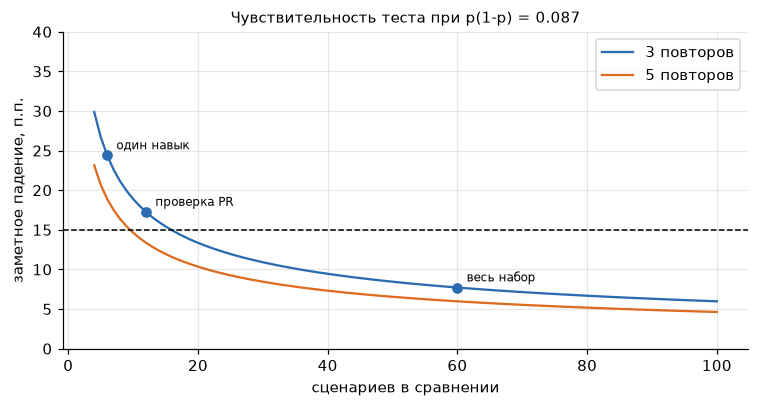

In [10]:
var_doc = three[three.doc].k.mul(3 - three[three.doc].k).div(6).mean()
n_range = np.arange(4, 101)
fig, ax = plt.subplots(figsize=(7, 3.8))
for k_runs, color in [(3, BLUE), (5, ORANGE)]:
    mde = [100 * minimum_detectable_effect(int(n), k_runs, var_doc) for n in n_range]
    ax.plot(n_range, mde, color=color, label=f"{k_runs} повторов")
ax.axhline(15, color="black", lw=1, ls="--")
for n, label in [(6, "один навык"), (12, "проверка PR"), (60, "весь набор")]:
    point = 100 * minimum_detectable_effect(n, 3, var_doc)
    ax.plot(n, point, "o", color=BLUE)
    ax.annotate(label, (n, point), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("сценариев в сравнении")
ax.set_ylabel("заметное падение, п.п.")
ax.set_title(f"Чувствительность теста при p(1-p) = {var_doc:.3f}")
ax.set_ylim(0, 40)
ax.legend()
fig.tight_layout()
table = pd.DataFrame(
    {
        f"{k} повторов": [
            round(100 * minimum_detectable_effect(n, k, var_doc)) for n in (6, 12, 60)
        ]
        for k in (3, 5)
    },
    index=["6 сценариев", "12 сценариев", "60 сценариев"],
)
for k_runs in (3, 5):
    need = next(n for n in range(1, 500) if minimum_detectable_effect(n, k_runs, var_doc) <= 0.15)
    print(f"Чтобы заметить падение 15 п.п. при {k_runs} повторах, нужно {need} сценариев")
table

**Вывод.** В трех ячейках из четырех все три повтора дают один и тот же результат, на документах чуть чаще. Но в четверти ячеек результат меняется от запуска к запуску, поэтому одного запуска мало. Средний разброс на документах около 0,09, это лучше худшего случая 0,25.

С тремя повторами проверка PR на 12 сценариях заметит падение примерно от 17 п.п. (процентных пунктов), а сценарии одного навыка по отдельности только от 24 п.п. Чтобы ловить падение в 15 п.п. на одном навыке, нужно около 16 сценариев с тремя повторами или около 10 с пятью. Это ответ на вопрос, сколько еще данных нужно, он пойдет в дизайн-документ.

## 4. Польза навыка

Для каждой пары задача и конфигурация, где есть по три запуска в обоих режимах, считаю разницу долей успеха с навыком и без него. Здесь таймаут считаю провалом.

In [11]:
paired = three.pivot_table(index=["config", "task"], columns="mode", values="k").dropna()
paired["lift"] = (paired["with"] - paired["without"]) / 3
paired = paired.reset_index().merge(tasks[["task", "doc_data"]], on="task")
lift_stats = paired.groupby("doc_data").lift.agg(
    pairs="size",
    mean="mean",
    helps=lambda s: (s > 0).mean(),
    no_change=lambda s: (s == 0).mean(),
    hurts=lambda s: (s < 0).mean(),
)
lift_stats.index = ["остальные задачи", "документы и данные"]
by_task = paired.groupby("task").lift.agg(["min", "max"])
opposite = by_task[(by_task["max"] >= 2 / 3) & (by_task["min"] <= -2 / 3)]
print(f"Задач, где навык сильно помогает одной модели и сильно мешает другой {len(opposite)}")
print(f"из {len(by_task)}")
lift_stats

Задач, где навык сильно помогает одной модели и сильно мешает другой 8
из 72


,pairs,mean,helps,no_change,hurts
остальные задачи,602,0.19,0.38,0.51,0.12
документы и данные,236,0.09,0.29,0.58,0.13


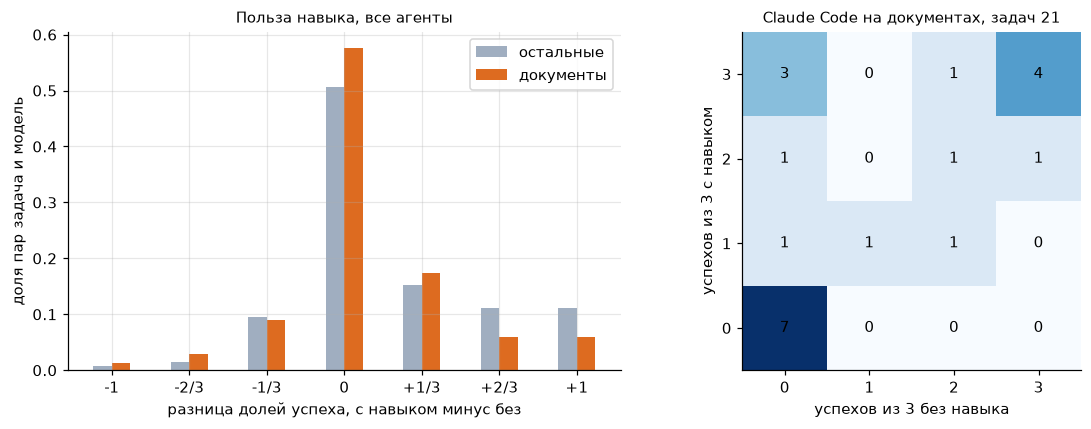

In [12]:
cc_cell = cc.groupby(["task", "mode"]).passed.agg(["sum", "size"]).reset_index()
cc_cell = cc_cell[cc_cell["size"] == 3].pivot(index="task", columns="mode", values="sum").dropna()
cc_doc = cc_cell[cc_cell.index.isin(tasks[tasks.doc_data].task)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
values = np.arange(-3, 4) / 3
for doc, color, label in [(False, GRAY, "остальные"), (True, ORANGE, "документы")]:
    lifts = paired[paired.doc_data == doc].lift.round(2)
    counts = lifts.value_counts(normalize=True).reindex(values.round(2), fill_value=0)
    offset = 0.04 if doc else -0.04
    ax1.bar(values + offset, counts.values, width=0.08, color=color, label=label)
ax1.set_xticks(values, ["-1", "-2/3", "-1/3", "0", "+1/3", "+2/3", "+1"])
ax1.set_xlabel("разница долей успеха, с навыком минус без")
ax1.set_ylabel("доля пар задача и модель")
ax1.set_title("Польза навыка, все агенты")
ax1.legend()

grid = pd.crosstab(cc_doc["with"], cc_doc["without"]).reindex(
    index=range(4), columns=range(4), fill_value=0
)
ax2.imshow(grid.values, cmap="Blues", origin="lower")
for i in range(4):
    for j in range(4):
        ax2.text(j, i, grid.values[i, j], ha="center", va="center")
ax2.set_xticks(range(4))
ax2.set_yticks(range(4))
ax2.grid(False)
ax2.set_xlabel("успехов из 3 без навыка")
ax2.set_ylabel("успехов из 3 с навыком")
ax2.set_title(f"Claude Code на документах, задач {len(cc_doc)}")
fig.tight_layout()

In [13]:
floor = int(((cc_doc["with"] == 0) & (cc_doc["without"] == 0)).sum())
ceiling = int(((cc_doc["with"] == 3) & (cc_doc["without"] == 3)).sum())
print(f"Не решаются ни в одном режиме {floor} из {len(cc_doc)}")
print(f"Решаются всегда в обоих режимах {ceiling} из {len(cc_doc)}")

Не решаются ни в одном режиме 7 из 21
Решаются всегда в обоих режимах 4 из 21


**Вывод.** В среднем навык помогает, на документах примерно на 9 п.п. Но в половине пар он ничего не меняет, а примерно в каждой восьмой паре снижает результат. На 8 задачах из 72 один и тот же навык сильно помогает одной модели и сильно мешает другой. Значит, навык нужно проверять на той модели, с которой он работает, и прогонять заново после смены модели. Это подтверждает требование из раздела 1.

У Claude Code на документах 7 задач из 21 не решаются ни с навыком, ни без, а 4 решаются всегда. На первых поломку навыка не увидеть вообще, на вторых не видна польза. Значит, сценарии стенда надо подбирать по бейзлайну. С навыком агент должен решать их почти всегда, а без навыка не всегда.

## 5. Как агент использует навыки

В логах Claude Code вызов навыка виден как инструмент Skill с текстом «Launching skill» и названием навыка. Беру 216 запусков Claude Code с навыками.

In [14]:
with_skills = cc[cc["mode"] == "with"].copy()
with_skills["opened"] = with_skills.n_skill_calls > 0
opened_by_doc = with_skills.groupby("doc_data").opened.mean()
print(f"Агент открыл хотя бы один навык в {with_skills.opened.mean():.0%} запусков")
print(f"на документах в {opened_by_doc[True]:.0%}")
print(f"OpenHands с Opus 4.8 в {openhands_use.opened_skill.mean():.0%}")
first = with_skills.first_skill_call.dropna()
print(f"Номер вызова, на котором агент открыл навык, медиана {first.median():.0f}")

opened_pairs = {
    (task, name)
    for task, names in zip(with_skills.task, with_skills.skills_opened.fillna(""), strict=True)
    for name in names.split("|")
    if name
}
offered = skills[skills.task.isin(with_skills.task)]
pairs = zip(offered.task, offered.skill, strict=True)
never = 1 - np.mean([pair in opened_pairs for pair in pairs])
print(f"Навыков, которые агент не открыл ни в одном из трех запусков {never:.0%}")

Агент открыл хотя бы один навык в 62% запусков
на документах в 70%
OpenHands с Opus 4.8 в 84%
Номер вызова, на котором агент открыл навык, медиана 1
Навыков, которые агент не открыл ни в одном из трех запусков 51%


,"запусков, где он был",открыл
навык,,
xlsx,36,0.58
pdf,33,0.27
pptx,9,0.67
docx,6,0.50


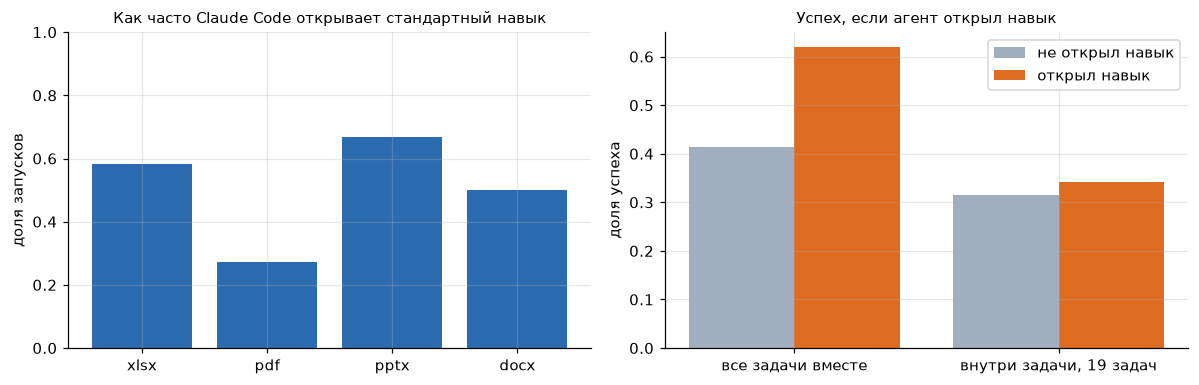

In [15]:
standard = []
for name in ["xlsx", "pdf", "pptx", "docx"]:
    runs = with_skills[with_skills.task.isin(skills[skills.skill == name].task)]
    hit = runs.skills_opened.fillna("").str.split("|").map(lambda names, n=name: n in names)
    standard.append({"навык": name, "запусков, где он был": len(runs), "открыл": hit.mean()})
standard = pd.DataFrame(standard).set_index("навык")

per_task = with_skills.groupby("task").opened.agg(["sum", "size"])
mixed = per_task[(per_task["sum"] > 0) & (per_task["sum"] < per_task["size"])].index
mixed_runs = with_skills[with_skills.task.isin(mixed)]
within = mixed_runs.groupby(["task", "opened"]).passed.mean().unstack()
naive = with_skills.groupby("opened").passed.mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.bar(standard.index, standard["открыл"], color=BLUE)
ax1.set_ylim(0, 1)
ax1.set_title("Как часто Claude Code открывает стандартный навык")
ax1.set_ylabel("доля запусков")
x = np.arange(2)
ax2.bar(x - 0.2, [naive[False], within[False].mean()], 0.4, color=GRAY, label="не открыл навык")
ax2.bar(x + 0.2, [naive[True], within[True].mean()], 0.4, color=ORANGE, label="открыл навык")
ax2.set_xticks(x, ["все задачи вместе", f"внутри задачи, {len(mixed)} задач"])
ax2.set_ylabel("доля успеха")
ax2.set_title("Успех, если агент открыл навык")
ax2.legend()
fig.tight_layout()
standard

**Вывод.** По логу точно видно, какой навык открыл агент и на каком шаге. Обычно он решает это в начале, на первом или втором вызове. Значит, выбор навыка зависит в основном от описания.

Claude Code открыл навык в 62% запусков, на документах в 70%. Половину предложенных навыков агент не открыл ни разу за три запуска. Навык pdf он открывал только в каждом четвертом запуске, где тот был. В 19 задачах агент в одних запусках открывал навык, а в других нет. Так что выбор навыка тоже случаен, и долю открытий нужно мерить по повторам, как и успех.

Если сравнивать все запуски вместе, с навыком агент решает задачу заметно чаще, 62% против 41%. Но внутри одной задачи разница почти исчезает. Значит, общая разница появилась в основном из-за того, что задачи разные. Поэтому в стенде версии сравниваются только внутри одного сценария.

Отдельно видно, что Anthropic уже переписал описания xlsx и pdf. В актуальной версии описание xlsx выросло примерно с 60 до 150 слов и прямо говорит, когда навык брать, а когда нет. Ровно такие правки описаний стенд и должен проверять.

## 6. Время запуска и проверка PR

Время в логе разбито на подготовку окружения, работу агента и проверку. Цены и токенов в данных нет, поэтому смотрю только время.

In [16]:
doc_runs = cc[cc.doc_data]
parts = {
    "окружение": doc_runs.environment_setup_s,
    "агент": doc_runs.agent_s,
    "проверка": doc_runs.verifier_s,
    "весь запуск": doc_runs.total_s,
}
time_table = pd.DataFrame(
    {name: (s.dropna() / 60).quantile([0.5, 0.9, 1.0]).values for name, s in parts.items()},
    index=["медиана, мин", "90-й процентиль, мин", "максимум, мин"],
)
time_table

,окружение,агент,проверка,весь запуск
"медиана, мин",0.21,2.50,0.13,4.49
"90-й процентиль, мин",3.88,10.95,0.28,24.96
"максимум, мин",28.70,28.50,1.07,55.35


,"медиана, мин",доля не дольше 40 минут
как в SkillsBench,56.67,0.05
образ собран заранее,47.05,0.20
образ заранее и лимит 10 минут,27.39,1.00


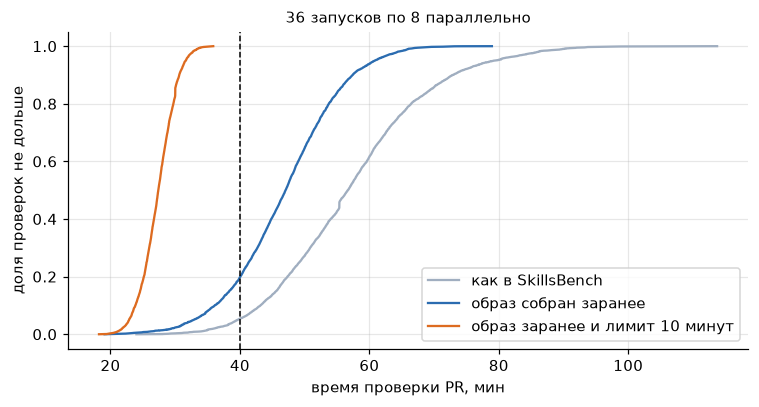

In [17]:
rng = np.random.default_rng(0)


def check_time(durations: np.ndarray, runs: int = 36, workers: int = 8) -> float:
    """Wall time of one PR check in minutes, runs go to the first free worker."""
    free_at = [0.0] * workers
    for duration in rng.choice(durations, runs):
        heapq.heapreplace(free_at, free_at[0] + duration)
    return max(free_at) / 60


as_is = doc_runs.total_s.dropna().to_numpy()
no_setup = (doc_runs.total_s - doc_runs.environment_setup_s.fillna(0)).dropna().to_numpy()
variants = {
    "как в SkillsBench": as_is,
    "образ собран заранее": no_setup,
    "образ заранее и лимит 10 минут": np.minimum(no_setup, 600),
}
sims = {name: np.array([check_time(d) for _ in range(5000)]) for name, d in variants.items()}

fig, ax = plt.subplots(figsize=(7, 3.8))
for (name, values), color in zip(sims.items(), [GRAY, BLUE, ORANGE], strict=True):
    ax.plot(np.sort(values), np.linspace(0, 1, len(values)), color=color, label=name)
ax.axvline(40, color="black", lw=1, ls="--")
ax.set_xlabel("время проверки PR, мин")
ax.set_ylabel("доля проверок не дольше")
ax.set_title("36 запусков по 8 параллельно")
ax.legend()
fig.tight_layout()
pd.DataFrame(
    {
        "медиана, мин": {k: np.median(v) for k, v in sims.items()},
        "доля не дольше 40 минут": {k: (v <= 40).mean() for k, v in sims.items()},
    }
)

In [18]:
print(f"Запусков без подготовки окружения дольше 10 минут {(no_setup > 600).mean():.0%}")

Запусков без подготовки окружения дольше 10 минут 19%


**Вывод.** Медианный запуск на документах идет около 5 минут, но у времени длинный хвост. Каждый десятый запуск идет дольше 25 минут, а подготовка окружения иногда занимает почти полчаса. Если взять время как есть, проверка PR из 36 запусков займет около часа и в 40 минут почти никогда не уложится.

Сборка образа заранее помогает мало, медиана падает только до 47 минут. Основное время съедают долгие запуски самого агента. Укладывает проверку в 40 минут только лимит на запуск. С лимитом 10 минут проверка почти всегда идет меньше 30 минут, но на задачах SkillsBench лимит обрежет каждый пятый запуск.

Поэтому в стенде образы собираются заранее, на запуск ставится лимит 10 минут, а сценарии, которые на бейзлайне не укладываются в лимит, упрощаем или убираем. Наши сценарии проще задач SkillsBench, их длительность проверим на бейзлайне. Предположение из дизайн-документа «запуск до 6 минут» верно для медианы, но не для хвоста, это я исправлю.

## 7. Причины провалов

У SkillsBench есть аудит провалов для трех моделей в OpenHands. Смотрю, на какие причины он делит провалы и что видно из логов Claude Code без LLM.

Запусков с ошибкой окружения в логе 17%
доля успеха у них 35%, у остальных 47%


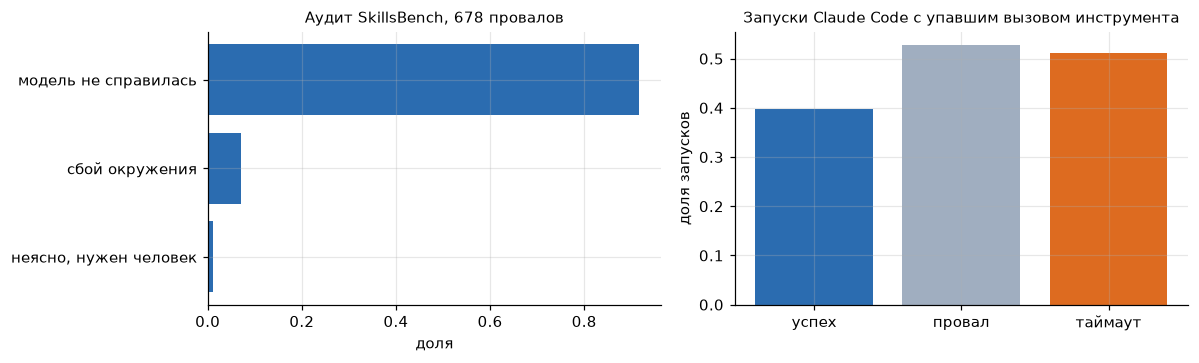

In [19]:
verdicts = audit.verdict.value_counts(normalize=True).rename(
    {
        "model_capability_failure": "модель не справилась",
        "infra_or_environment_failure": "сбой окружения",
        "unclear_needs_human_followup": "неясно, нужен человек",
    }
)
cc["any_failed_call"] = cc.n_failed_calls > 0
cc["environment_error"] = cc.n_environment_errors > 0
failed_share = cc.groupby("status").any_failed_call.mean().reindex(["pass", "fail", "timeout"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
ax1.barh(verdicts.index[::-1], verdicts.values[::-1], color=BLUE)
ax1.set_title(f"Аудит SkillsBench, {len(audit)} провалов")
ax1.set_xlabel("доля")
ax2.bar(["успех", "провал", "таймаут"], failed_share.values, color=[BLUE, GRAY, ORANGE])
ax2.set_title("Запуски Claude Code с упавшим вызовом инструмента")
ax2.set_ylabel("доля запусков")
fig.tight_layout()
env = cc.groupby("environment_error").passed.mean()
print(f"Запусков с ошибкой окружения в логе {cc.environment_error.mean():.0%}")
print(f"доля успеха у них {env[True]:.0%}, у остальных {env[False]:.0%}")

**Вывод.** Аудит SkillsBench делит провалы почти только на «модель не справилась» (92%) и «сбой окружения» (7%). Для нас это слишком грубо. Нам нужно знать, открыл ли агент нужный навык, взял ли чужой, пропустил ли шаг или ошибся сам навык. Готовой разметки с такими классами нет, поэтому сто провалов я размечу сам.

Упавший вызов инструмента есть почти в половине запусков, в том числе успешных. Агент часто пробует команду, получает ошибку и исправляется. Так что само по себе это не признак провала, и классификатору нужен весь лог, а не только ошибки. А вот ошибки окружения вроде «permission denied» и «command not found» правила находят легко. Они есть в 17% запусков, и такие запуски успешны реже. Это первый кандидат в правила бейзлайна для класса «сбой инфраструктуры».

Классы будут сильно несбалансированы, редких причин в ста провалах окажется мало. Поэтому кроме точности по всем классам смотрим полноту по каждому классу отдельно.

## 8. Описания навыков

Агент выбирает навык по описанию из SKILL.md. Смотрю длину описаний и то, насколько они похожи друг на друга. Сходство считаю как косинус между векторами TF-IDF, это грубая мера совпадения слов, смысл она не ловит.

Медиана длины описания 31 слов
Медиана длины текста навыка 642 слов
Навыков со скриптами 40%


,skill,nearest_skill,nearest
153,radar-vital-signs,radar-signal-processing,0.47
154,vital-sign-extraction,radar-vital-signs,0.38
182,search-attractions,search-restaurants,0.31
34,stepinfo-3d,simulation-metrics,0.30
91,conditioning,matched-filtering,0.29


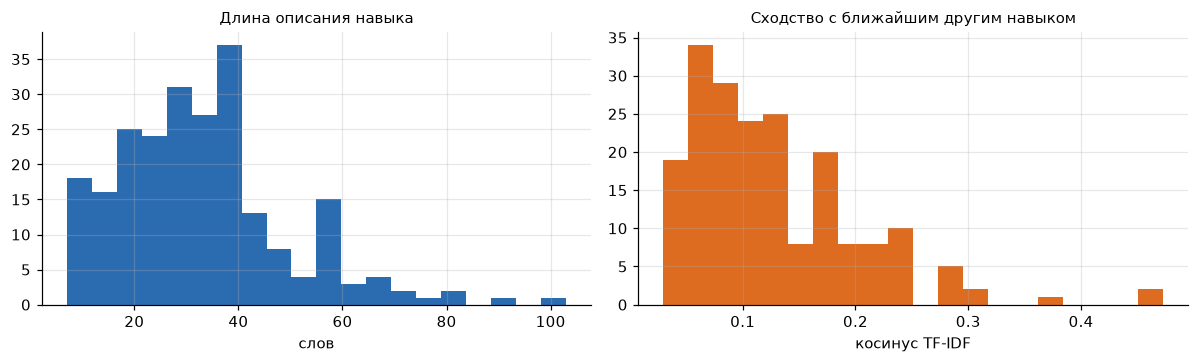

In [20]:
unique = skills.drop_duplicates("skill").reset_index(drop=True)
vectors = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), sublinear_tf=True)
matrix = vectors.fit_transform(unique.description.fillna(""))
similarity = cosine_similarity(matrix)
np.fill_diagonal(similarity, 0)
unique["nearest"] = similarity.max(axis=1)
unique["nearest_skill"] = unique.skill.to_numpy()[similarity.argmax(axis=1)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
ax1.hist(skills.description_words, bins=20, color=BLUE)
ax1.set_title("Длина описания навыка")
ax1.set_xlabel("слов")
ax2.hist(unique.nearest, bins=20, color=ORANGE)
ax2.set_title("Сходство с ближайшим другим навыком")
ax2.set_xlabel("косинус TF-IDF")
fig.tight_layout()
print(f"Медиана длины описания {skills.description_words.median():.0f} слов")
print(f"Медиана длины текста навыка {skills.body_words.median():.0f} слов")
print(f"Навыков со скриптами {skills.has_scripts.mean():.0%}")
top = unique.sort_values("nearest", ascending=False)[["skill", "nearest_skill", "nearest"]]
top.drop_duplicates("nearest").head(5)

**Вывод.** Описание навыка обычно занимает около 30 слов, а сам текст навыка около 640. Скрипты есть у 40% навыков. Похожих навыков в SkillsBench почти нет. Медиана сходства с ближайшим соседом 0,11, а самая похожая пара это два навыка про радар со сходством 0,47. Так что путаницу навыков на этих данных не проверить, для этого в MVP нужны свои двойники с похожими описаниями.

Для выбора соседа в проверке PR этой меры хватит, она дешевая и не требует модели. Если двойники окажутся похожи по смыслу, но не по словам, перейдем на эмбеддинги.

## 9. Что берем в стенд

| Что увидели | Что делаем в стенде |
|---|---|
| В четверти ячеек повторы расходятся, разброс около 0,09 | 3 повтора на сценарий, на спорных сценариях можно добавить еще 2 |
| С тремя повторами на 6 сценариях заметно только падение от 24 п.п. | Генератор делает около 16 вариантов сценария на навык, честно пишем в отчете, какое падение тест ловит |
| Если выбросить таймауты, доля успеха растет с 33% до 42% | Таймаут считаем провалом с отдельной причиной |
| Нет токенов и цены | Стенд пишет цену и время сам |
| Навык открыт в запусках без навыков | Проверяем лог, такой запуск недействителен |
| Треть задач на документы не решается никогда, пятая часть решается всегда | Сценарии отбираем по бейзлайну |
| Выбор навыка случаен и происходит в начале | Долю открытий меряем по повторам, правки описания проверяем на соседях |
| Разница «открыл или нет» исчезает внутри задачи | Сравниваем версии только внутри сценария |
| Из-за долгих запусков проверка PR идет около часа | Лимит 10 минут на запуск, образы собираем заранее, тяжелые сценарии убираем |
| Аудит SkillsBench различает только модель и окружение | Свои 7 причин, ручная разметка ста провалов |
| Похожих навыков в SkillsBench нет | Свои двойники, сосед по TF-IDF |